In [491]:
analysis_folder = r"F:\Analysis Scripts\analysis"
thermometry_folder = r"D:\LocalCode\pythermometry"

import sys
if analysis_folder not in sys.path:
	sys.path.append(analysis_folder)
if thermometry_folder not in sys.path:
	sys.path.append(thermometry_folder)
import json
import glob

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from data_class import Data
from library import MW_styles

from FermiFitter.physics import alphaViscEstimate, expansionParams
import helpers.constants as c
from helpers.gaussfit import gauss2dFit

In [492]:
ODT_insitu = Data(f"2026-10-28_C_e.csv").data
ODT_AR = np.mean(ODT_insitu["G.dy"]/ODT_insitu["G.dx"])

F:\Data\2026\*\*\*\2026-10-28_C_e.csv


In [493]:
dat = Data(f"2026-10-23_H_e.csv").data
dat = dat[dat["p1"] < 5]
dat["TOF"] = (dat["p1"] + 1.1)*1e-3 # in s. Also add 1.1 ms to account for time between image 1/2 and wait times

AR_data = dat.groupby("TOF").agg({'AR': ['mean', 'std']})

thermometry_dat = Data(f"2026-10-23_G_e_Unitary_NB73000.csv").data # this is mixed T and U shots, filter out T shots
thermometry_dat = thermometry_dat[thermometry_dat["p1"] < 5]
EoEF_est = thermometry_dat["ENoEF"].mean()

root = dat["imgfiles"][0].split("\\")[0]

settings_file = glob.glob(f"{root}\\*.json")[0]
with open(settings_file, "r") as file:
    settings = json.load(file)

wx, wy, wz = np.array(settings['fermifit3D_cfg']['trap_freqs'])*2*np.pi
lambda_factor = wx/np.mean([wz, wy]) 

F:\Data\2026\*\*\*\2026-10-23_H_e.csv
F:\Data\2026\*\*\*\2026-10-23_G_e_Unitary_NB73000.csv


In [ ]:
def scale_AR_and_plot(i, beta, wx, wy, wz, ROI, fit_area, len_TOF=20, plot=False):

    ARs = []

    TOF, fname = dat.loc[i, ["TOF", "imgfiles"]]

    tof_list = np.linspace(0.1e-3, TOF, len_TOF)

    # load OD
    fname = fname.split("\\")[-1]
    od_fpath = f"{root}\\plots\\{fname[:-4]}_OD.csv"
    od = np.loadtxt(od_fpath)
    od_crop = od[ROI[0]:ROI[1], ROI[2]:ROI[3]][fit_area[0]:fit_area[1], fit_area[2]+20:fit_area[3]-60]

    # Gaussian fit to find cloud center
    x, y = np.arange(od_crop.shape[1]), np.arange(od_crop.shape[0])
    popts, __ = gauss2dFit(x, y, od_crop)
    dx, dy, x0, y0, A, b = popts

    # scale to physical coordinates
    x, y = (x-x0)*c.pxedge, (y-y0)*c.pxedge 
    bx, by, __ = expansionParams(wx, wy, wz, TOF, beta) 

    if plot:
        fig, axs = plt.subplots(1, int(len_TOF/2), figsize=(int(len_TOF/2)*5, 3))
        n_abs = od_crop/c.R0

    # scale x-y coordinates by expansion params based on n \propto F(x/bx, y/by)
    for j, t in enumerate(tof_list):
        # numerically solve for expansion params based on TOF and shear visc. 
        bxt, byt, __ = expansionParams(wx, wy, wz, t, beta) 
        # scale dx and dy by bx, by to find modified aspect ratio
        dxt, dyt = dx*bxt/bx, dy*byt/by

        AR_t = (dyt/dxt)
        ARs.append(AR_t)

        if plot and j%2:
            xt, yt = x*bxt/bx, y*byt/by
            n_abs_t = n_abs*(by/byt)*(bx/byt)
            axs[int(j/2)].imshow(n_abs_t, extent=[xt.min(), xt.max(), yt.min(), yt.max()], aspect='equal')

    return tof_list*1e3, ARs # TOF in ms

In [497]:
def scale_AR(beta, wx, wy, wz, TOF, AR0, len_TOF=20, plot=False):

    ARs = []
    tof_list = np.linspace(0.1e-3, TOF, len_TOF)

    # scale x-y coordinates by expansion params based on n \propto F(x/bx, y/by)
    for t in tof_list:
        # numerically solve for expansion params based on TOF and shear visc. 
        bxt, byt, __ = expansionParams(wx, wy, wz, t, beta) 
        # scale dx and dy by bx, by to find modified aspect ratio

        # dxt, dyt = dxi*bxt, dyi*byt
        # AR_t = (dyt/dxt)

        AR_t = AR0 * (byt/bxt)
        ARs.append(AR_t)

        # check using insitu images

    return tof_list*1e3, ARs # TOF in ms

In [498]:
AR0=0.37
tmax = np.max(dat["TOF"])
ltof = 40

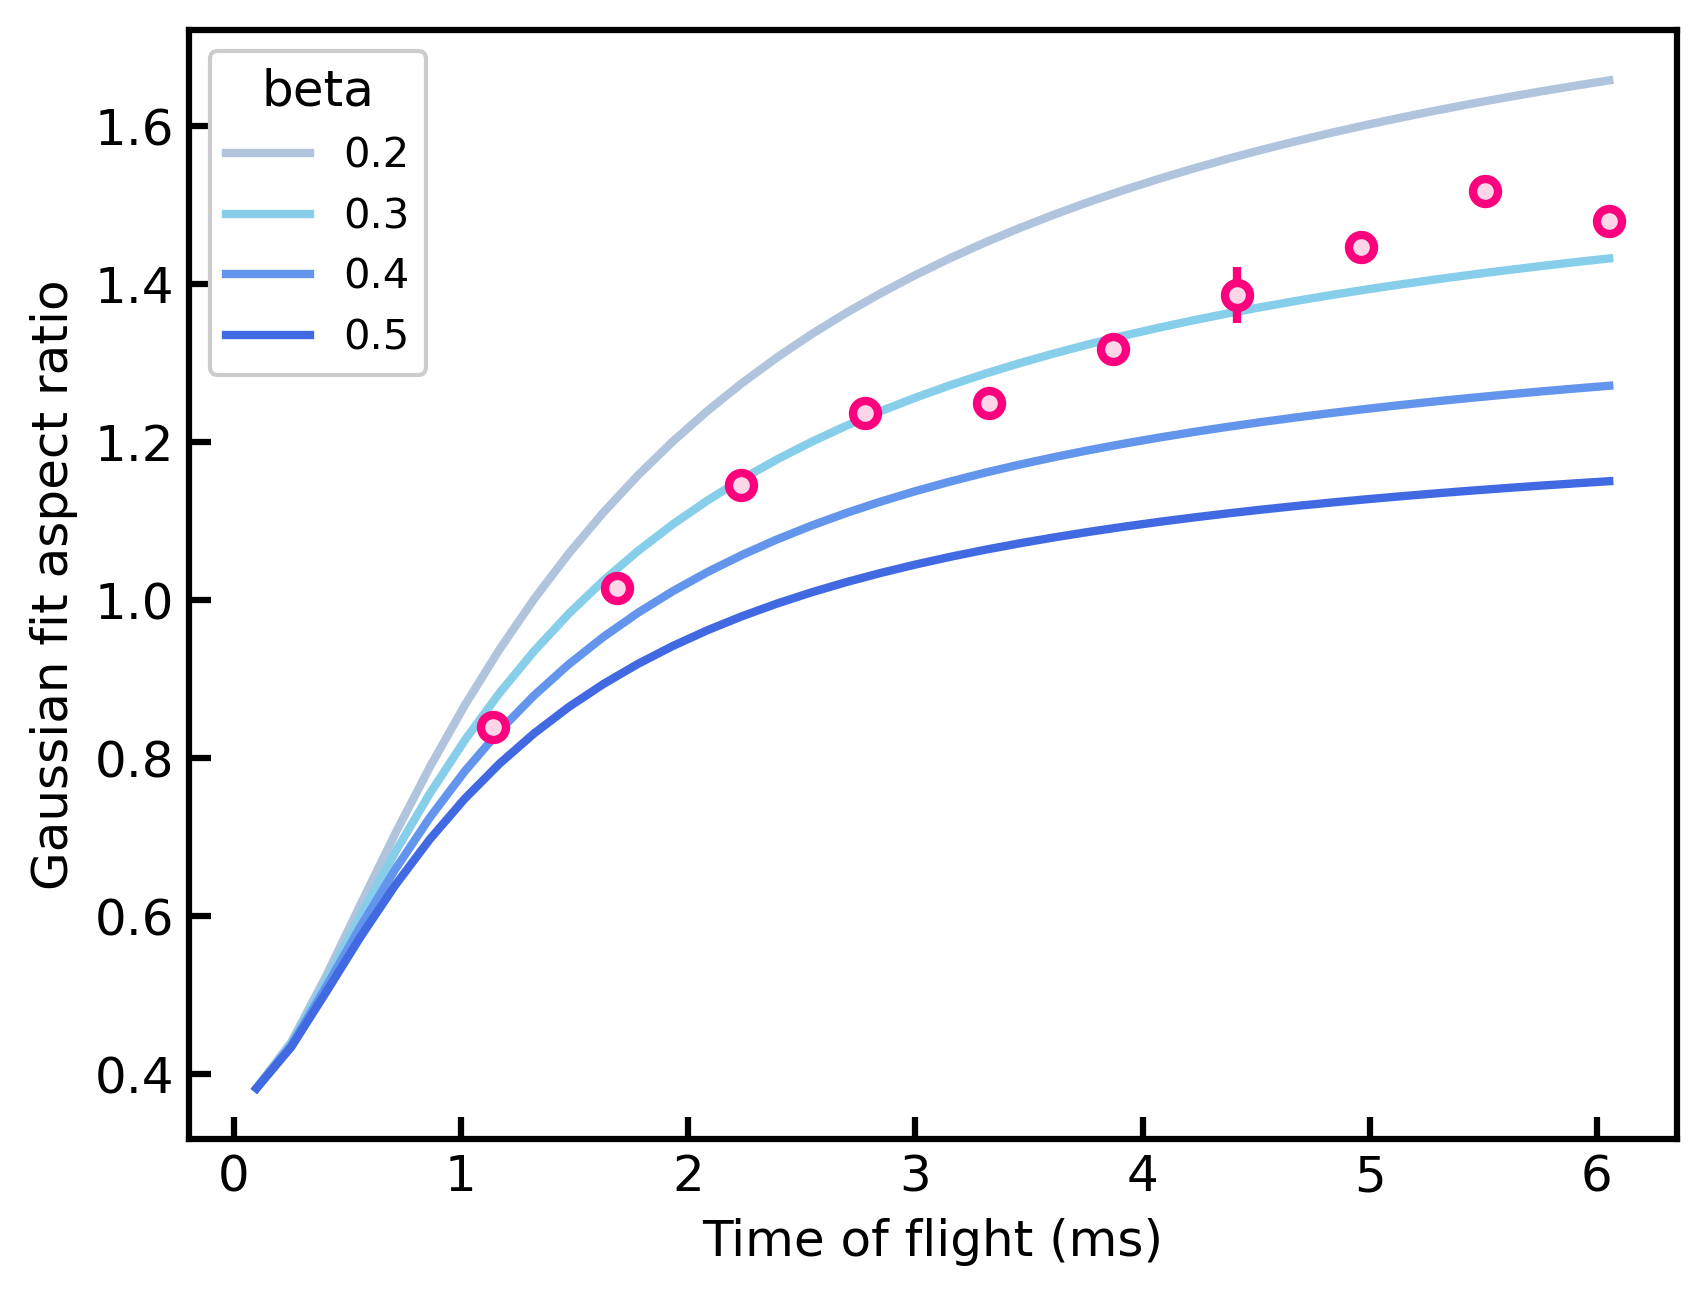

In [499]:
beta_list = [0.2, 0.3, 0.4, 0.5]
colors = ["lightsteelblue", "skyblue", "cornflowerblue", "royalblue", "midnightblue"]
i = 21
t_list = []
AR_list = []

for b in beta_list:
    t, AR = scale_AR(b, wx, wy, wz, tmax, AR0, ltof)
    t_list.append(t)
    AR_list.append(AR)

for i, b in enumerate(beta_list):
    if i == 0:
        label = f"{b}"
    else:
        label= f"{b}"
    plt.plot(t_list[i], AR_list[i], ls="-", marker="", color=colors[i], label=label)

plt.errorbar(AR_data.index*1e3, AR_data["AR"]["mean"], AR_data["AR"]["std"], **MW_styles[0])
plt.xlabel("Time of flight (ms)")
plt.ylabel("Gaussian fit aspect ratio")
plt.legend(title=f"beta")

In [481]:
dat1 = Data(f"2026-10-26_C_e.csv").data
dat2 = Data(f"2026-10-26_D_e.csv").data # shots 30 and prev are mixed U/TShots
dat1 = dat1[dat1["TOF"]<6.1]
dat1 = dat1[dat1["TOF"]>5.2]
dat2 = dat2[dat2["TOF"]<5]
dat1["TOF"] = (dat1["TOF"] + 1.6)*1e-3 # in s. Also add 1.1 ms to account for time between image 1/2 and wait times
dat2["TOF"] = (dat2["TOF"] + 1.1)*1e-3 # in s. Also add 1.1 ms to account for time between image 1/2 and wait times

thermometry_dat = Data("2026-10-26_D_e_first30shots.csv").data.iloc[1::2] # this is mixed T and U shots, filter out T shots
thermometry_dat.dropna(inplace=True)
EoEF_est = thermometry_dat["ENoEF"].mean()

dat3 = pd.DataFrame(thermometry_dat["AR"])
dat3["TOF"] = 6.6*1e-3

dat = pd.concat([dat1, dat2, dat3], ignore_index=True)
AR_data = dat.groupby("TOF").agg({'AR': ['mean', 'std']})

root = dat["imgfiles"][0].split("\\")[0]

settings_file = glob.glob(f"{root}\\*.json")[0]
with open(settings_file, "r") as file:
    settings = json.load(file)

wx, wy, wz = np.array(settings['fermifit3D_cfg']['trap_freqs'])*2*np.pi
lambda_factor = wx/np.mean([wz, wy]) 

F:\Data\2026\*\*\*\2026-10-26_C_e.csv
F:\Data\2026\*\*\*\2026-10-26_D_e.csv
F:\Data\2026\*\*\*\2026-10-26_D_e_first30shots.csv


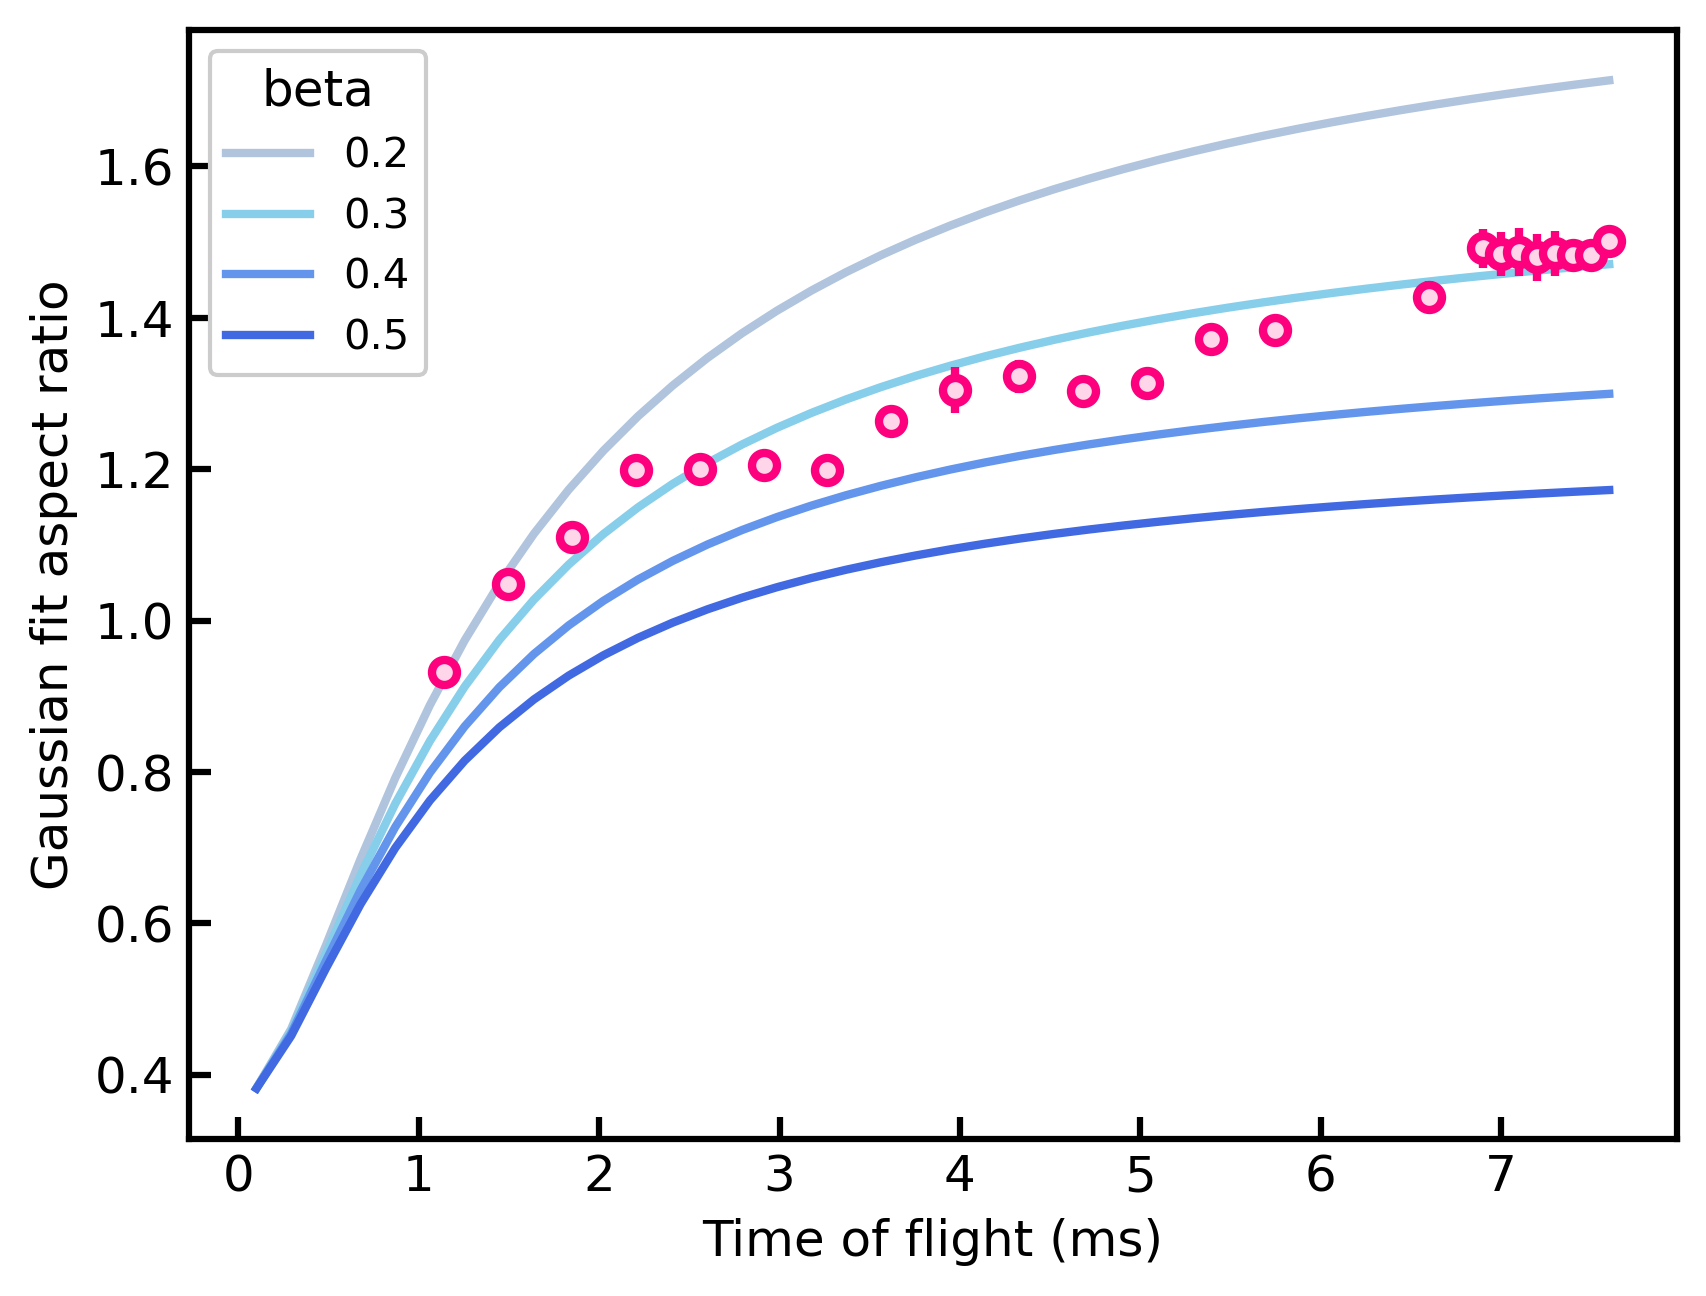

In [482]:
AR0 = 0.37
tmax = np.max(dat["TOF"])
ltof = 40

beta_list = [0.2, 0.3, 0.4, 0.5]
colors = ["lightsteelblue", "skyblue", "cornflowerblue", "royalblue", "midnightblue"]
i = 21
t_list = []
AR_list = []

for b in beta_list:
    t, AR = scale_AR(b, wx, wy, wz, tmax, AR0, ltof)
    t_list.append(t)
    AR_list.append(AR)

for i, b in enumerate(beta_list):
    if i == 0:
        label = f"{b}"
    else:
        label= f"{b}"
    plt.plot(t_list[i], AR_list[i], ls="-", marker="", color=colors[i], label=label)
    
plt.errorbar(AR_data.index*1e3, AR_data["AR"]["mean"], AR_data["AR"]["std"], **MW_styles[0])
plt.xlabel("Time of flight (ms)")
plt.ylabel("Gaussian fit aspect ratio")
plt.legend(title=f"beta")

In [ ]:
from scipy.optimize import curve_fit

def fit_scale_AR(tof_list, beta, AR0):
    # t in s

    ARs = []
    # scale x-y coordinates by expansion params based on n \propto F(x/bx, y/by)
    for t in tof_list:
        # numerically solve for expansion params based on TOF and shear visc. 
        bxt, byt, __ = expansionParams(wx, wy, wz, t, beta) 
        # scale dx and dy by bx, by to find modified aspect ratio
        ARs.append(AR0*byt/bxt)

    return ARs # TOF in ms

popts, pcov = curve_fit(fit_scale_AR, AR_data.index, AR_data["AR"]["mean"], sigma = AR_data["AR"]["std"], p0=[0.3, 0.37])
perrs = np.sqrt(np.diag(pcov))

xfit = np.linspace(AR_data.index.min(), AR_data.index.max(), 40)
yfit = fit_scale_AR(xfit, *popts)

<>:10: SyntaxWarning: invalid escape sequence '\p'
<>:19: SyntaxWarning: invalid escape sequence '\p'
<>:10: SyntaxWarning: invalid escape sequence '\p'
<>:19: SyntaxWarning: invalid escape sequence '\p'
C:\Users\coldatoms\AppData\Local\Temp\ipykernel_19140\1547543642.py:10: SyntaxWarning: invalid escape sequence '\p'
  label=f"{popts[0]:.2f}$\pm${perrs[0]:.2f} (fit)"
C:\Users\coldatoms\AppData\Local\Temp\ipykernel_19140\1547543642.py:19: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(1,1, marker="", ls="", label=f"AR$_0$={popts[1]:.2f}$\pm${perrs[1]:.2f}")


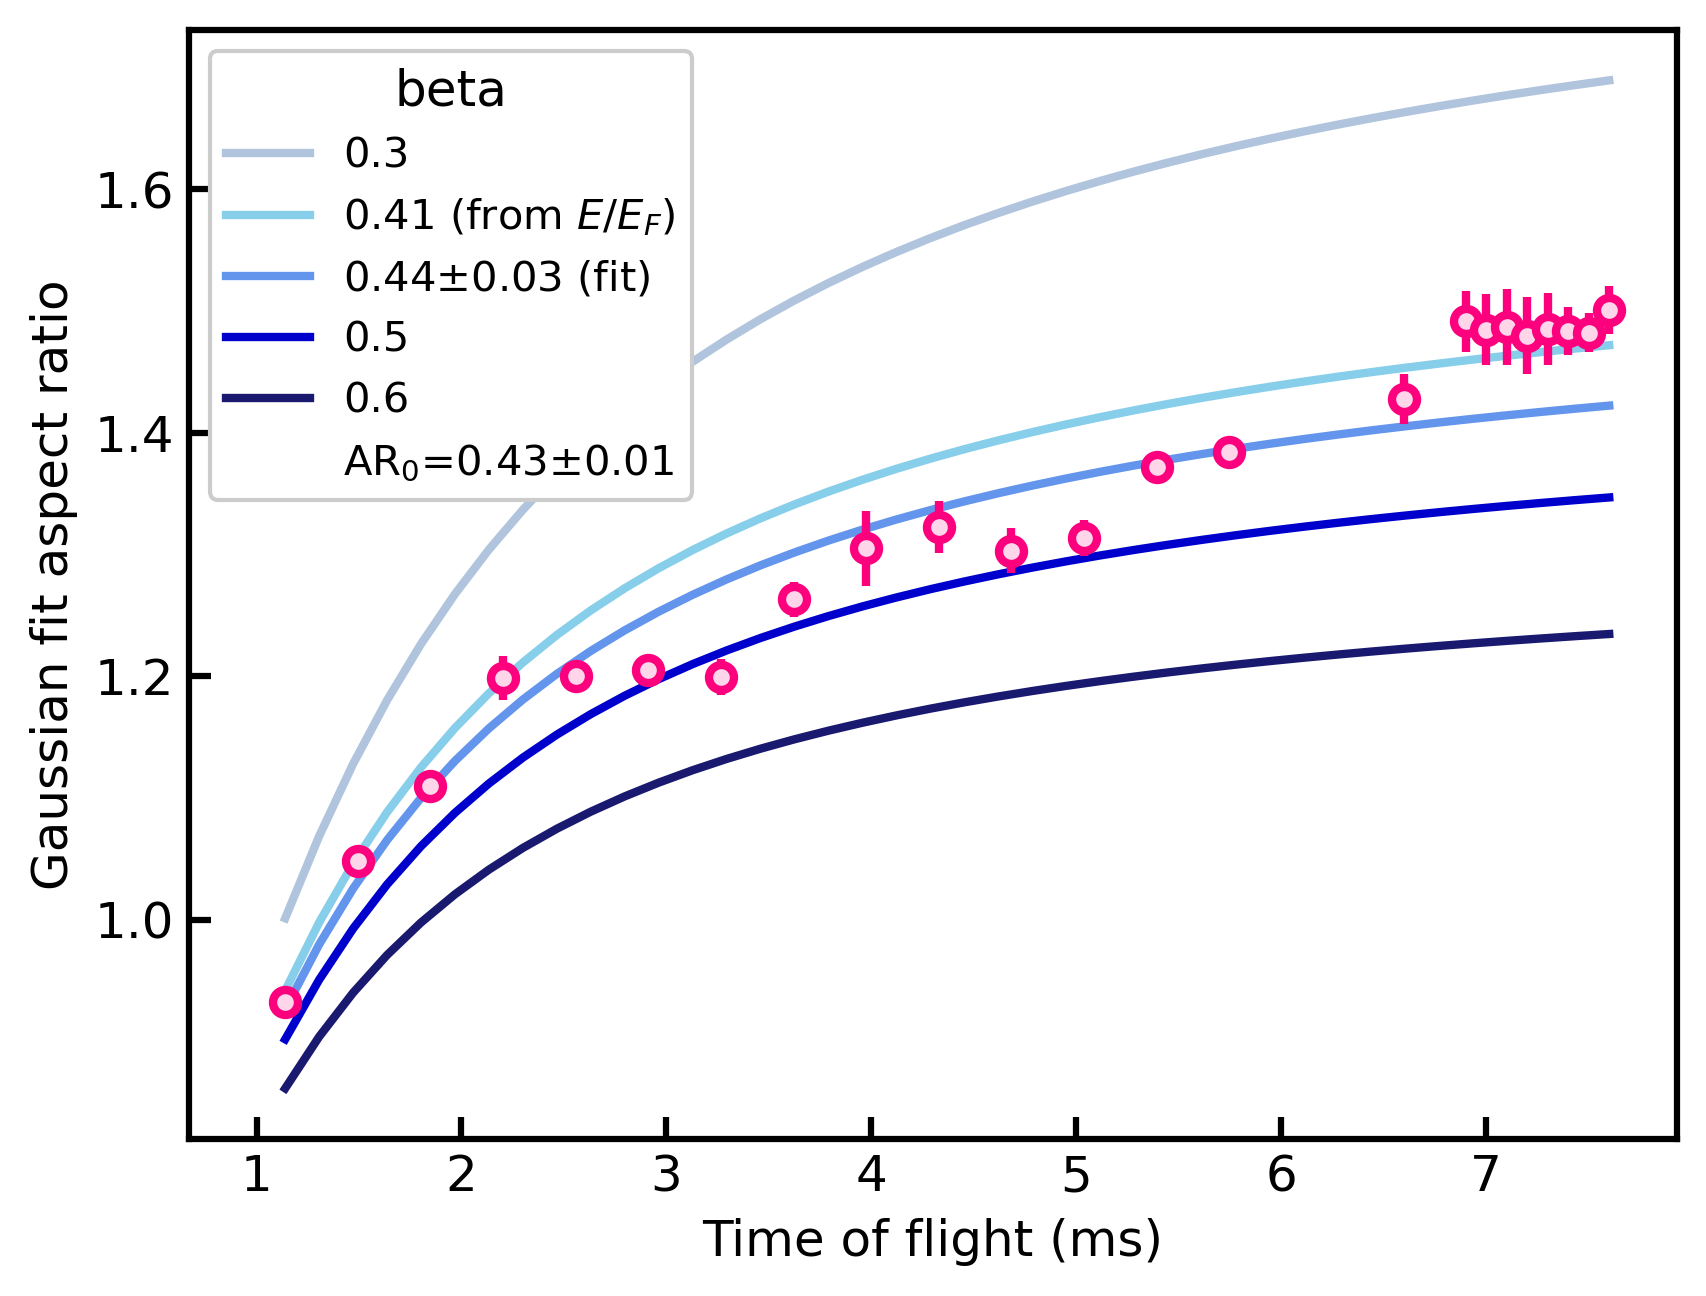

In [ ]:
beta_th = alphaViscEstimate(EoEF_est)  / (EoEF_est) / (3**(1/3))
beta_th *= (0.00354 / lambda_factor)**(1/3)

beta_list = np.sort([0.3, beta_th, 0.5, 0.6, popts[0]])
colors = ["lightsteelblue", "skyblue", "cornflowerblue", "mediumblue", "midnightblue"]
AR0 = popts[1]

for i, b in enumerate(beta_list):
    if b == popts[0]:
        label=f"{popts[0]:.2f}$\pm${perrs[0]:.2f} (fit)"
    elif b == beta_th:
        label=f"{b:.2f} (from $E/E_F$)"
    else:
        label = b
    plt.plot(xfit*1e3, fit_scale_AR(xfit, b, AR0), ls="-", marker="", color=colors[i], label=label)

plt.errorbar(AR_data.index*1e3, AR_data["AR"]["mean"], AR_data["AR"]["std"], **MW_styles[0])

plt.plot(1,1, marker="", ls="", label=f"AR$_0$={popts[1]:.2f}$\pm${perrs[1]:.2f}")
plt.xlabel("Time of flight (ms)")
plt.ylabel("Gaussian fit aspect ratio")
plt.legend(loc=2, title="beta")

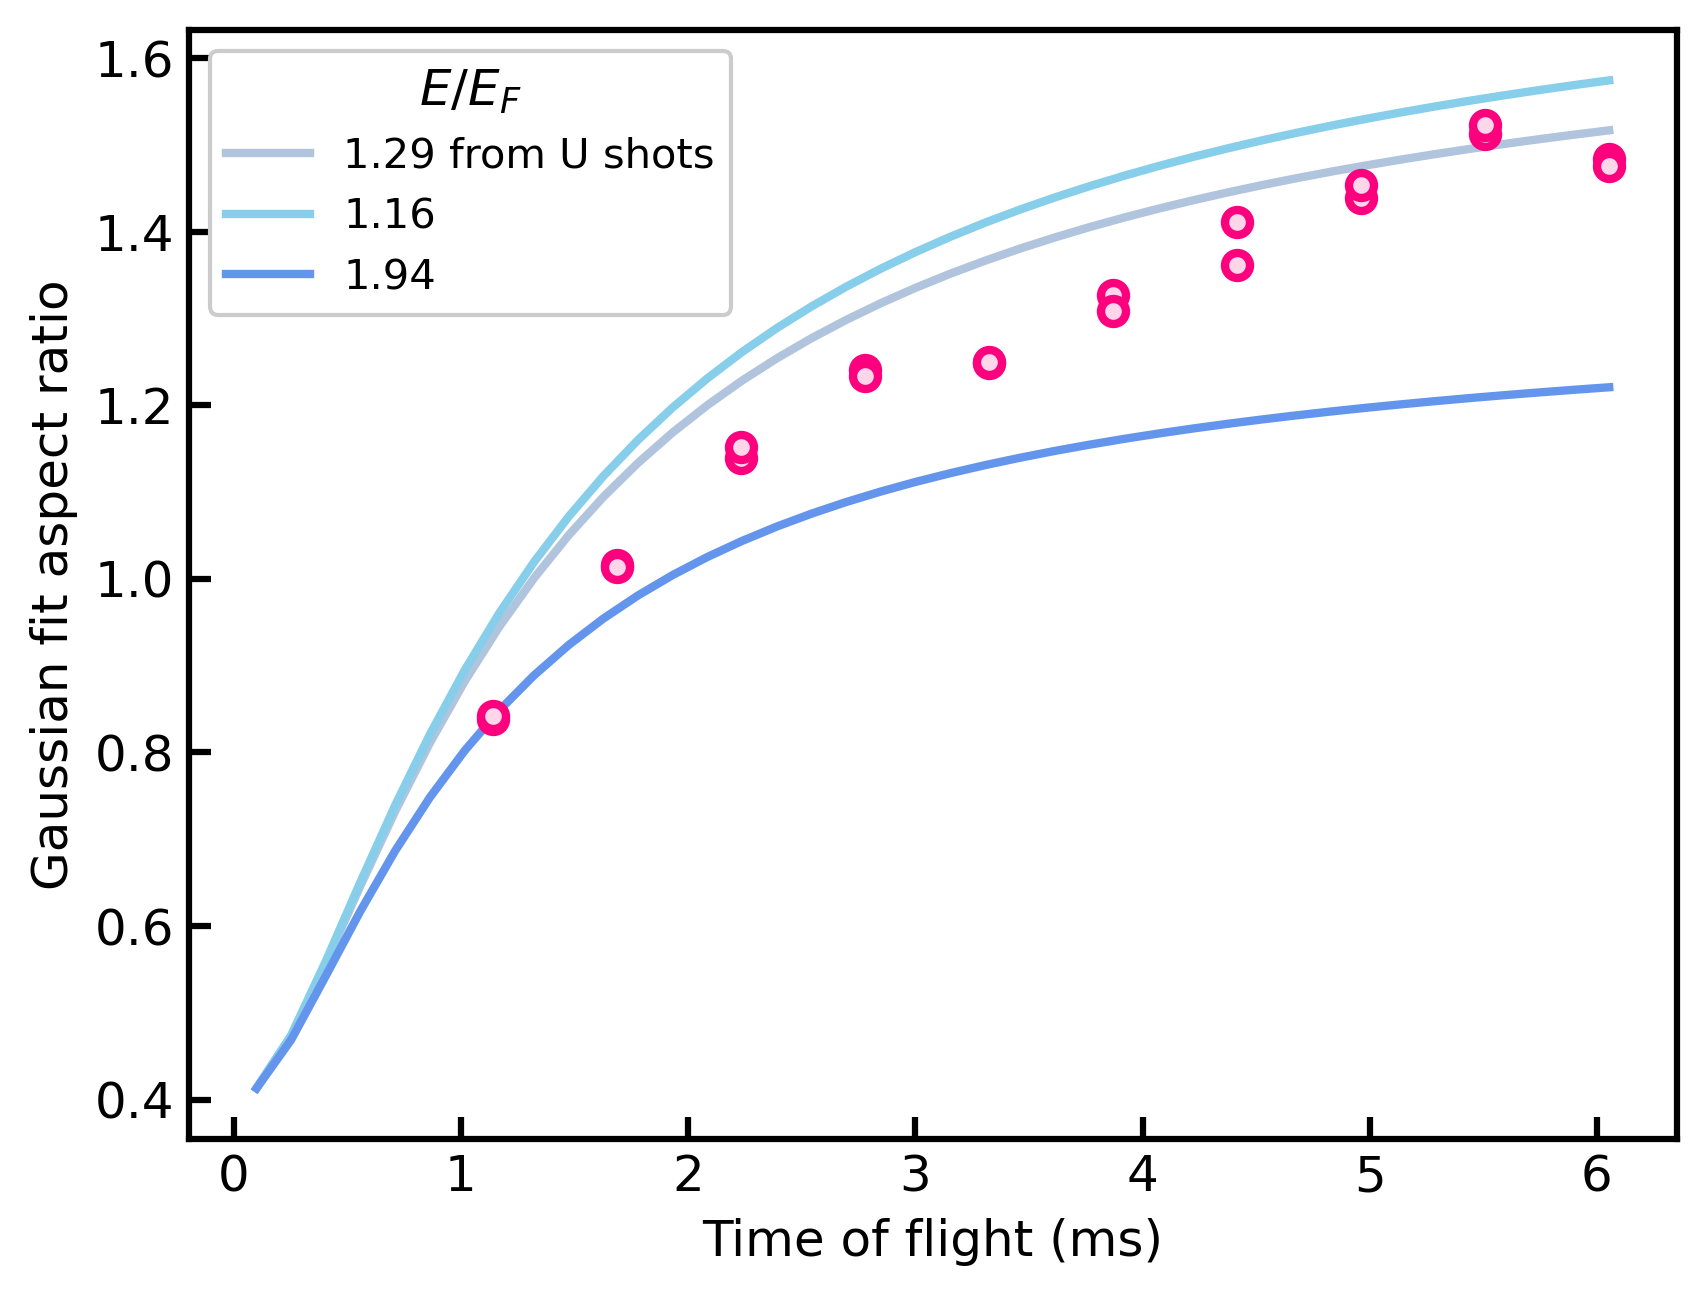

In [ ]:
# plot by energy
EoEF_list = EoEF_est*np.array([1, 0.9, 1.5])
colors = ["lightsteelblue", "skyblue", "cornflowerblue", "royalblue", "midnightblue"]
t_list = []
AR_list = []

for EoEF in EoEF_list:
    beta = alphaViscEstimate(EoEF) / (EoEF) / (3**(1/3))
    beta *= (0.00354 / lambda_factor)**(1/3)
    t, AR = scale_AR(beta, wx, wy, wz, tmax, AR0, ltof)
    t_list.append(t)
    AR_list.append(AR)

for i, E in enumerate(EoEF_list):
    if i == 0:
        label = f"{E:.2f} from U shots"
    else:
        label= f"{E:.2f}"
    plt.plot(t_list[i], AR_list[i], ls="-", marker="", color=colors[i], label=label)
    
plt.plot(dat["TOF"]*1e3, dat["AR"], **MW_styles[0])
plt.xlabel("Time of flight (ms)")
plt.ylabel("Gaussian fit aspect ratio")
plt.legend(title=f"$E/E_F$")
